# Analyze Classifier AUROC per batch

In [2]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from plot_utils import *
letter_dict_rev = {v: k for k, v in letter_dict.items()}
channel_dict_rev = {v: k for k, v in channel_dict.items()}

# letter_dict_rev
channel_list = list(channel_dict_rev.values())[:-3]
channel_list

%matplotlib inline
## Disable truncation globally
# pl.Config.set_tbl_rows(20)  # Show all rows
# pl.Config.set_tbl_cols(40)  # Show all columns

## define control types
TC = ["EGFP"]
NC = ["RHEB", "MAPK9", "PRKACB", "SLIRP"]
PC = ["ALK", "ALK_Arg1275Gln", "PTK2B"]
cNC = ["Renilla"]
cPC = ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
       "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]

FEAT_SETS = ["DNA", "Mito", "GFP", "AGP", "Morph"]
PLATEMAP_DIR = "../../../8.2_updated_snakemake_pipeline/inputs/metadata/platemaps/{batch_id}/platemap/"
CLASS_RES_DIR = "../../../8.2_updated_snakemake_pipeline/outputs/classification_analyses/"

In [4]:
BIO_REP_BATCHES = ["2025_01_27_Batch_13", "2025_01_28_Batch_14"]
COMBINED_BIO_REP_DIR = "2025_01_Batch_13-14"
IMG_QC_DIR = f"../../../8.3_downstream_analysis_runxi/outputs/{COMBINED_BIO_REP_DIR}"
# OUTPUT_DIR = f"../../../3_outputs/1_snakemake_pipeline/3.smp_results_analyses/3.classification_analyses/{COMBINED_BIO_REP_DIR}"
# if not os.path.exists(OUTPUT_DIR):
#     os.makedirs(OUTPUT_DIR)

In [90]:
clin_var_info = pl.read_csv(
    "/home/shenrunx/igvf/varchamp/2025_laval_submitted/1_allele_collection/3_outputs/varchamp_consolidated_alleles_clinvar_gnomad.tsv",
    separator="\t", infer_schema_length=10000
)
clin_var_info = clin_var_info.with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("allele_0")
)
clin_var_info

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af,allele_0
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,f64,str
2,"""GBA""","""160G>C""","""Val54Leu""","""ENSG00000177628""","""1""",155240033,"""NC_000001.11:155240033:C:G""","""ALE0000584""","""CCSBVarC000001""","""6""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""F12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""G""","""C""","""1-155240033-G-C""",null,"""GBA_Val54Leu"""
2,"""GBA""","""670C>T""","""Leu224Phe""","""ENSG00000177628""","""1""",155238225,"""NC_000001.11:155238225:G:A""","""ALE00000002""","""CCSBVarC000002""","""73""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""C12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""C""","""T""","""1-155238225-C-T""",null,"""GBA_Leu224Phe"""
2,"""GBA""","""887G>A""","""Arg296Gln""","""ENSG00000177628""","""1""",155237453,"""NC_000001.11:155237453:C:T""","""ALE00000003""","""CCSBVarC000003""","""113""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""D12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19367.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.887G>A (p.…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic""",1.0,"""Feb 09, 2024""",7.8973108e7,"""-""","""RCV000004573|RCV000079357|RCV0…","""MONDO:MONDO:0011945,MedGen:C18…","""Gaucher disease perinatal leth…","""germline;unknown""","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55237453e8,1.55237453e8,"""1q22""","""criteria provided, multiple su…",15.0,"""-""","""N""","""ClinGen:CA221417,UniProtKB:P04…",3.0,4328.0,1.55237453e8,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000232587|SCV000321701|SCV0…","""-""","""-""","""887G>A ""","""Arg296Gln""","""NM_000157.4""",2.0,"""1_Pathogenic""","""chr1""","""G""","""A""","""1-155237453-G-A""",null,"""GBA_Arg296Gln"""
2,"""GBA""","""1448T>C""","""Leu483Pro""","""ENSG00000177628""","""1""",155235252,"""NC_000001.11:155235252:A:G""","""ALE00000004""","""CCSBVarC000004""","""231""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""E12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19327.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.1448T>C (p…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic; risk factor""",1.0,"""Nov 27, 2024""",421016.0,"""-""","""RCV000004509|RCV000004511|RCV0…","""MONDO:MONDO:0009266,MedGen:C02…","""Gaucher disease type II|Gauche…","""biparental;de novo;germ

In [6]:
img_well_qc_sum = pl.read_csv(f"{IMG_QC_DIR}/plate-well-level_img_qc_sum.csv")
img_well_qc_sum = img_well_qc_sum.with_columns(
    pl.col("channel").replace("DAPI", "DNA").alias("channel")
)
img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
    pl.col("is_bg").max().alias("is_bg"),
    pl.col("s2n_ratio").mean().alias("s2n_ratio")
).with_columns(pl.lit("Morph").alias("channel"))
img_well_qc_sum = pl.concat([
    img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
], how="vertical_relaxed")

# img_well_qc_sum["channel"].unique()
# img_well_qc_sum_gfp = img_well_qc_sum.filter(pl.col("channel")=="GFP").with_columns(
#     pl.col("plate").alias("Metadata_Plate"),
#     pl.col("well").alias("Metadata_Well"),
# )

In [139]:
class_info_dir = "{}/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells/metrics.csv"
class_res_df_batch = pl.DataFrame()

for batch_id in BIO_REP_BATCHES:
    class_res_df = pl.read_csv(class_info_dir.format(CLASS_RES_DIR, batch_id))
    # Define your edge‐detecting regex once
    edge_regex = r"(?:01|P|A|24)"
    # Now create a new column “Edge_Status” with three cases:
    #  • “both_edge” if both well_0 and well_1 match the regex
    #  • “one_edge”  if exactly one of them matches
    #  • “no_edge”   otherwise
    class_res_df = class_res_df.with_columns([
        pl.when(
            (pl.col("well_0").str.contains(edge_regex)) & 
            (pl.col("well_1").str.contains(edge_regex))
        )
        .then(pl.lit("both_edge"))
        .when(
            (pl.col("well_0").str.contains(edge_regex)) | 
            (pl.col("well_1").str.contains(edge_regex))
        )
        .then(pl.lit("one_edge"))
        .otherwise(pl.lit("no_edge"))
        .alias("Edge_Status")
    ])    
    # display(class_res_df.filter(pl.col("Edge_Status")=="both_edge"))
    for channel in channel_list:
        class_res_df_channel = class_res_df.filter(pl.col("Metadata_Feature_Type")==channel)
        class_res_df_channel = class_res_df_channel.join(
            img_well_qc_sum.filter(pl.col("channel")==channel).select(pl.col(["plate","well","is_bg"])),
            left_on=["Plate","well_0"],
            right_on=["plate","well"]
        ).rename({"is_bg": "well_0_is_bg"})
        class_res_df_channel = class_res_df_channel.join(
            img_well_qc_sum.filter(pl.col("channel")==channel).select(pl.col(["plate","well","is_bg"])),
            left_on=["Plate","well_1"],
            right_on=["plate","well"]
        ).rename({"is_bg": "well_1_is_bg"})
        class_res_df_batch = pl.concat([class_res_df_batch, class_res_df_channel])
        
        plate_maps = sorted(set(["_".join(pm.split("_")[:-1]) for pm in class_res_df_channel["Plate"].unique()]))
        for pm in plate_maps:
            class_res_ch_pm = class_res_df_channel.filter(pl.col("Plate").str.contains(pm))
            plates = sorted(class_res_ch_pm["Plate"].unique().to_list())
            
            fig, axes = plt.subplots(2,2,figsize=(48,23)) ## sharey=True,sharex=True
            for plate in plates:
                plate_info = class_res_ch_pm.filter(pl.col("Plate")==plate)
                ## plot the ctrls alleles first
                # plate_info_ctrl = plate_info.filter(pl.col("Metadata_Control"))
                # ctrls_wells = pl.concat([plate_info_ctrl["well_0"], plate_info_ctrl["well_1"]]).unique()
                # agg_group_by_well_0 = plate_info_ctrl.group_by("well_0","allele_0").agg([
                #     pl.col("AUROC").mean().alias("AUROC_Mean"),
                #     pl.col("well_0_is_bg").max().alias("is_bg")
                # ]).rename(
                #     {"well_0": "well", "allele_0": "allele"}
                # )#.with_columns(pl.col("Well_On_Edge").cast(pl.Boolean).alias("Well_On_Edge"))
                # agg_group_by_well_1 = plate_info_ctrl.filter(
                #     (pl.col("well_1").is_in(ctrls_wells))&\
                #     (~pl.col("well_1").is_in(agg_group_by_well_0["well"]))
                # ).group_by("well_1","allele_1").agg([
                #     pl.col("AUROC").mean().alias("AUROC_Mean"),
                #     pl.col("well_1_is_bg").max().alias("is_bg")
                # ]).rename(
                #     {"well_1": "well", "allele_1": "allele"}
                # )
                # agg_group_by_well_ctrl = pl.concat(
                #     [
                #         agg_group_by_well_0.select(pl.col("well","AUROC_Mean","allele","is_bg")),
                #         agg_group_by_well_1.select(pl.col("well","AUROC_Mean","allele","is_bg"))
                #     ]
                # )
                # ## plot the auroc per each plate for a platemap
                # plot_platemap(
                #     agg_group_by_well,
                #     plate+f"_{channel}",
                #     well_pos_col="well",
                #     # this is the column to color by (categorical or continuous)
                #     value_col="AUROC_Mean",
                #     # these columns will be concatenated into the annotation text
                #     label_cols=("allele","AUROC_Mean"),
                #     ax=axes[plates.index(plate)//2, plates.index(plate)%2],
                #     value_type="continuous",   # or "continuous"
                #     continuous_cmap="vlag",  # matplotlib colormap for continuous mode
                #     categorical_colors={True: "tomato", False: "skyblue"},     # dict for categorical → color
                #     grid_square="is_bg"
                # )

                ## plot the variant alleles
                plate_info_var_wt = plate_info.filter(~pl.col("Metadata_Control"))
                agg_group_by_var_well = plate_info_var_wt.group_by("well_0","allele_0").agg([
                    pl.col("AUROC").mean().alias("AUROC_Mean"),
                    pl.col("well_0_is_bg").max().alias("well0_is_bg"),
                    pl.col("well_1_is_bg").max().alias("well1_is_bg")
                ]).rename(
                    {"well_0": "well", "allele_0": "allele"}
                ).with_columns(
                    pl.max_horizontal(["well0_is_bg", "well1_is_bg"]).alias("is_bg"),
                    # pl.col("Well_On_Edge").cast(pl.Boolean).alias("Well_On_Edge"))
                )
                ## plot the auroc per each plate for a platemap
                plot_platemap(
                    agg_group_by_var_well,
                    plate+f"_{channel}",
                    well_pos_col="well",
                    # this is the column to color by (categorical or continuous)
                    value_col="AUROC_Mean",
                    # these columns will be concatenated into the annotation text
                    label_cols=("allele","AUROC_Mean"),
                    ax=axes[plates.index(plate)//2, plates.index(plate)%2],
                    value_type="continuous",   # or "continuous"
                    continuous_cmap="vlag",  # matplotlib colormap for continuous mode
                    categorical_colors={True: "tomato", False: "skyblue"},     # dict for categorical → color
                    grid_square="is_bg"
                )
                
            fig.subplots_adjust(wspace=-.55, hspace=.05)
            plt.tight_layout()

In [140]:
sns.boxenplot(data=class_res_df_batch.filter((~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(~pl.col("well_0_is_bg"))&(~pl.col("well_1_is_bg"))).to_pandas(), x="Edge_Status", y="AUROC")

ValueError: min() arg is an empty sequence

## Batch 7-8, 15-16

shape: (201, 8)
┌──────┬──────────────┬─────────────┬────────────┬─────────────┬─────────────┬───────┬─────────────┐
│ well ┆ allele       ┆ Edge_Status ┆ AUROC_Mean ┆ well0_is_bg ┆ well1_is_bg ┆ is_bg ┆ Edge_Binary │
│ ---  ┆ ---          ┆ ---         ┆ ---        ┆ ---         ┆ ---         ┆ ---   ┆ ---         │
│ str  ┆ str          ┆ str         ┆ f64        ┆ bool        ┆ bool        ┆ bool  ┆ bool        │
╞══════╪══════════════╪═════════════╪════════════╪═════════════╪═════════════╪═══════╪═════════════╡
│ B06  ┆ DES_Asp343As ┆ no_edge     ┆ 0.652323   ┆ false       ┆ false       ┆ false ┆ false       │
│      ┆ n            ┆             ┆            ┆             ┆             ┆       ┆             │
│ A23  ┆ ALAS2_Asp122 ┆ one_edge    ┆ 0.676772   ┆ false       ┆ false       ┆ false ┆ true        │
│      ┆ Asn          ┆             ┆            ┆             ┆             ┆       ┆             │
│ I03  ┆ ACSF3_Pro243 ┆ one_edge    ┆ 0.9833     ┆ false       ┆ false     

ComputeError: found multiple elements in the same group, please specify an aggregation function

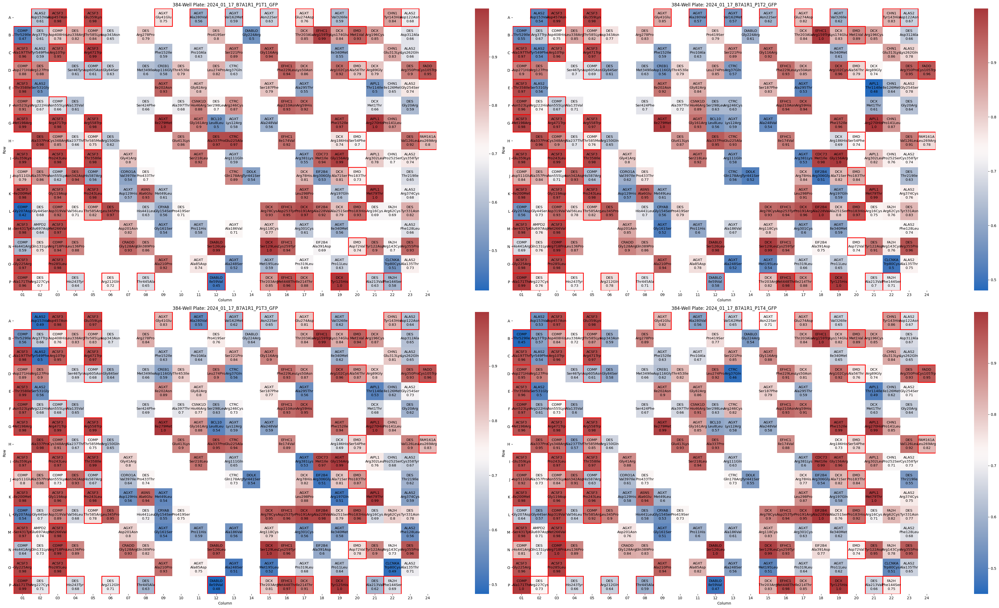

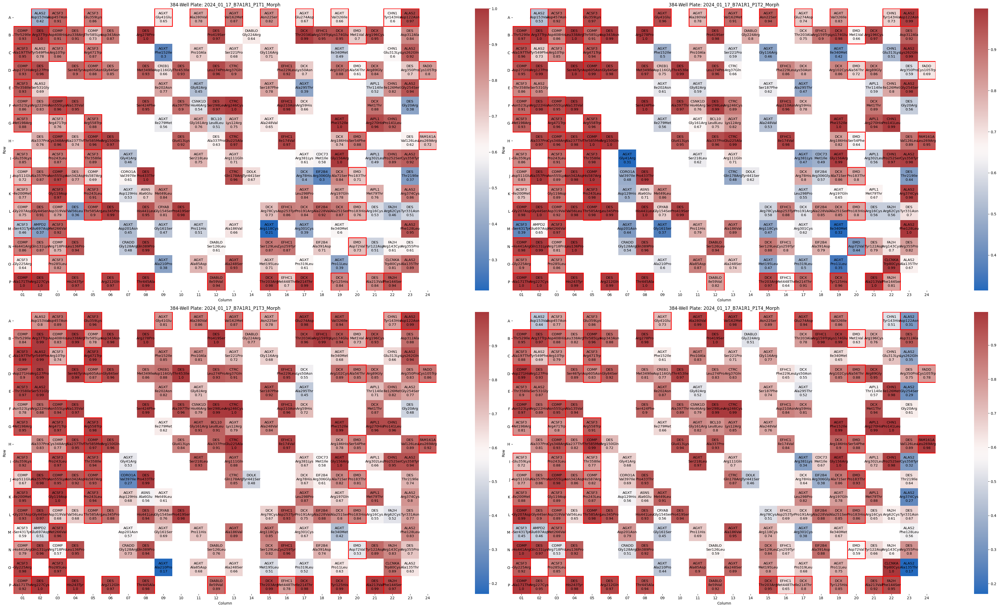

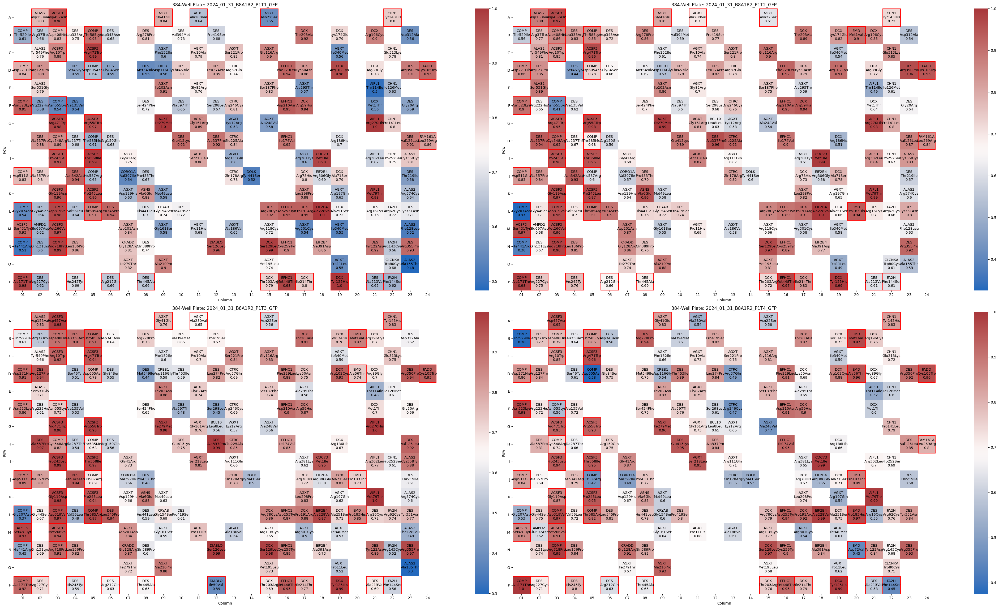

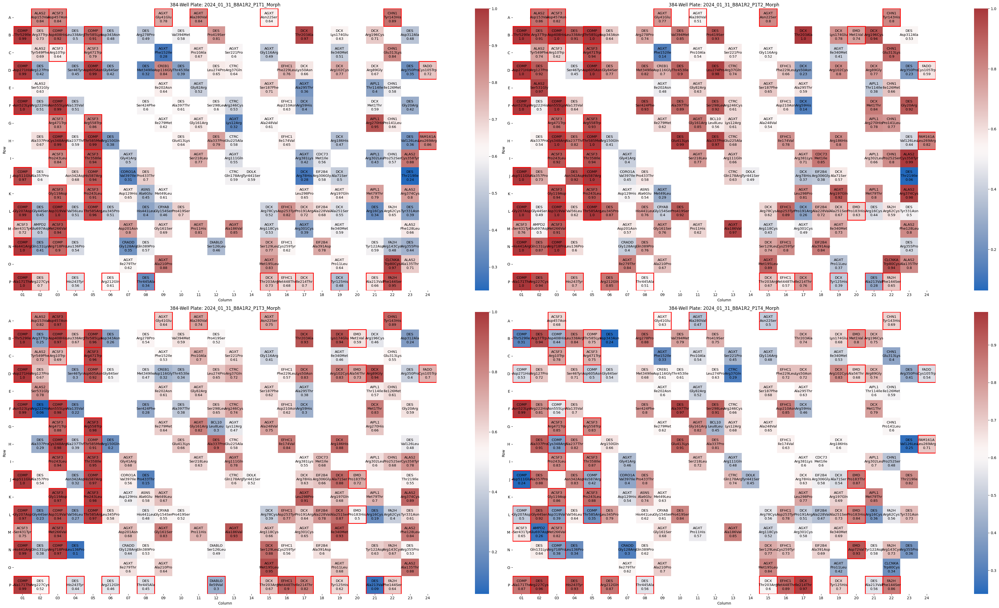

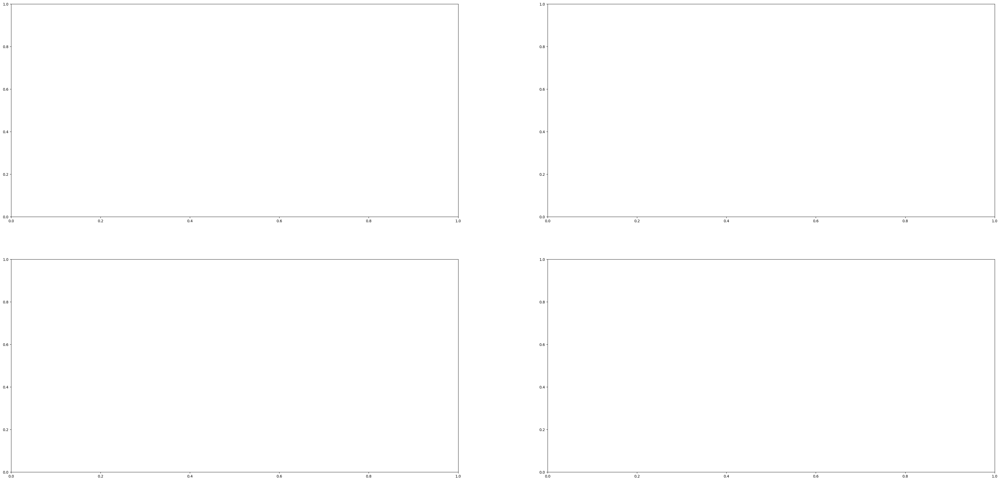

In [161]:
BATCH_DICTS = {
    "2024_02_Batch_7-8": ["2024_01_23_Batch_7", "2024_02_06_Batch_8"],
    "2025_03_Batch_15-16": ["2025_03_17_Batch_15", "2025_03_17_Batch_16"]
}
class_res_df_batch = pl.DataFrame()
for combined_bio_rep, bio_rep_batches in BATCH_DICTS.items():
    img_qc_dir = f"../../../8.3_downstream_analysis_runxi/outputs/{combined_bio_rep}"
    img_well_qc_sum = pl.read_csv(f"{img_qc_dir}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")

    for batch_id in bio_rep_batches:
        class_res_df = pl.read_csv(class_info_dir.format(CLASS_RES_DIR, batch_id))
        # Define your edge‐detecting regex once
        edge_regex = r"(?:01|P|A|24)"
        # Now create a new column “Edge_Status” with three cases:
        #  • “both_edge” if both well_0 and well_1 match the regex
        #  • “one_edge”  if exactly one of them matches
        #  • “no_edge”   otherwise
        class_res_df = class_res_df.with_columns([
            pl.when(
                (pl.col("well_0").str.contains(edge_regex)) & 
                (pl.col("well_1").str.contains(edge_regex))
            )
            .then(pl.lit("both_edge"))
            .when(
                (pl.col("well_0").str.contains(edge_regex)) | 
                (pl.col("well_1").str.contains(edge_regex))
            )
            .then(pl.lit("one_edge"))
            .otherwise(pl.lit("no_edge"))
            .alias("Edge_Status"),
            pl.when(pl.col("Full_Classifier_ID").str.contains("true"))
            .then(pl.lit("GFP"))
            .otherwise(pl.lit("Morph"))
            .alias("Metadata_Feature_Type")
        ])
        # display(class_res_df.filter(pl.col("Edge_Status")=="both_edge"))
        # display(img_well_qc_sum)
        
        for channel in ["GFP", "Morph"]:
            class_res_df_channel = class_res_df.filter(pl.col("Metadata_Feature_Type")==channel)
            class_res_df_channel = class_res_df_channel.join(
                img_well_qc_sum.filter(pl.col("channel")==channel).select(pl.col(["plate","well","is_bg"])),
                left_on=["Plate","well_0"],
                right_on=["plate","well"]
            ).rename({"is_bg": "well_0_is_bg"})
            class_res_df_channel = class_res_df_channel.join(
                img_well_qc_sum.filter(pl.col("channel")==channel).select(pl.col(["plate","well","is_bg"])),
                left_on=["Plate","well_1"],
                right_on=["plate","well"]
            ).rename({"is_bg": "well_1_is_bg"})
            class_res_df_batch = pl.concat([class_res_df_batch, class_res_df_channel])
            
            # print(class_res_df_channel["Plate"].unique())
            plate_maps = sorted(set([pm.split("T")[0] for pm in class_res_df_channel["Plate"].unique()]))
            for pm in plate_maps:
                # print(pm)
                class_res_ch_pm = class_res_df_channel.filter(pl.col("Plate").str.contains(pm))
                plates = sorted(class_res_ch_pm["Plate"].unique().to_list())
                fig, axes = plt.subplots(2,2,figsize=(48,23)) ## sharey=True,sharex=True
                for plate in plates:
                    plate_info = class_res_ch_pm.filter(pl.col("Plate")==plate)
                    
            #         ## plot the ctrls alleles first
            #         # plate_info_ctrl = plate_info.filter(pl.col("Metadata_Control"))
            #         # ctrls_wells = pl.concat([plate_info_ctrl["well_0"], plate_info_ctrl["well_1"]]).unique()
            #         # agg_group_by_well_0 = plate_info_ctrl.group_by("well_0","allele_0").agg([
            #         #     pl.col("AUROC").mean().alias("AUROC_Mean"),
            #         #     pl.col("well_0_is_bg").max().alias("is_bg")
            #         # ]).rename(
            #         #     {"well_0": "well", "allele_0": "allele"}
            #         # )#.with_columns(pl.col("Well_On_Edge").cast(pl.Boolean).alias("Well_On_Edge"))
            #         # agg_group_by_well_1 = plate_info_ctrl.filter(
            #         #     (pl.col("well_1").is_in(ctrls_wells))&\
            #         #     (~pl.col("well_1").is_in(agg_group_by_well_0["well"]))
            #         # ).group_by("well_1","allele_1").agg([
            #         #     pl.col("AUROC").mean().alias("AUROC_Mean"),
            #         #     pl.col("well_1_is_bg").max().alias("is_bg")
            #         # ]).rename(
            #         #     {"well_1": "well", "allele_1": "allele"}
            #         # )
            #         # agg_group_by_well_ctrl = pl.concat(
            #         #     [
            #         #         agg_group_by_well_0.select(pl.col("well","AUROC_Mean","allele","is_bg")),
            #         #         agg_group_by_well_1.select(pl.col("well","AUROC_Mean","allele","is_bg"))
            #         #     ]
            #         # )
            #         # ## plot the auroc per each plate for a platemap
            #         # plot_platemap(
            #         #     agg_group_by_well,
            #         #     plate+f"_{channel}",
            #         #     well_pos_col="well",
            #         #     # this is the column to color by (categorical or continuous)
            #         #     value_col="AUROC_Mean",
            #         #     # these columns will be concatenated into the annotation text
            #         #     label_cols=("allele","AUROC_Mean"),
            #         #     ax=axes[plates.index(plate)//2, plates.index(plate)%2],
            #         #     value_type="continuous",   # or "continuous"
            #         #     continuous_cmap="vlag",  # matplotlib colormap for continuous mode
            #         #     categorical_colors={True: "tomato", False: "skyblue"},     # dict for categorical → color
            #         #     grid_square="is_bg"
            #         # )
    
                    ## plot the variant alleles
                    plate_info_var_wt = plate_info.filter(~pl.col("Metadata_Control"))
                    agg_group_by_var_well = plate_info_var_wt.group_by("well_0","allele_0","Edge_Status").agg([
                        pl.col("AUROC").mean().alias("AUROC_Mean"),
                        pl.col("well_0_is_bg").max().alias("well0_is_bg"),
                        pl.col("well_1_is_bg").max().alias("well1_is_bg")
                    ]).rename(
                        {"well_0": "well", "allele_0": "allele"}
                    ).with_columns(
                        pl.max_horizontal(["well0_is_bg", "well1_is_bg"]).alias("is_bg"),
                        pl.when(pl.col("Edge_Status")=="no_edge")
                        .then(pl.lit(False))
                        .otherwise(pl.lit(True))
                        .alias("Edge_Binary")
                    )
                    # print(agg_group_by_var_well)
                    # agg_group_by_var_well = plate_info_var_wt.with_columns(
                    #     # pl.max_horizontal(["well0_is_bg", "well1_is_bg"]).alias("is_bg"),
                    #     pl.when(pl.col("Edge_Status")=="no_edge")
                    #     .then(pl.lit(False))
                    #     .otherwise(pl.lit(True))
                    #     .alias("Edge_Binary")
                    # )
                    # ## plot the auroc per each plate for a platemap
                    plot_platemap(
                        agg_group_by_var_well,
                        plate+f"_{channel}",
                        well_pos_col="well",
                        # this is the column to color by (categorical or continuous)
                        value_col="AUROC_Mean",
                        # these columns will be concatenated into the annotation text
                        label_cols=("allele","AUROC_Mean"),
                        ax=axes[plates.index(plate)//2, plates.index(plate)%2],
                        value_type="continuous",   # or "continuous"
                        continuous_cmap="vlag",  # matplotlib colormap for continuous mode
                        categorical_colors={True: "tomato", False: "skyblue"},     # dict for categorical → color
                        grid_square="Edge_Binary"
                    )
                fig.subplots_adjust(wspace=-.55, hspace=.05)
                plt.tight_layout()
                break

<Axes: xlabel='Edge_Status', ylabel='AUROC'>

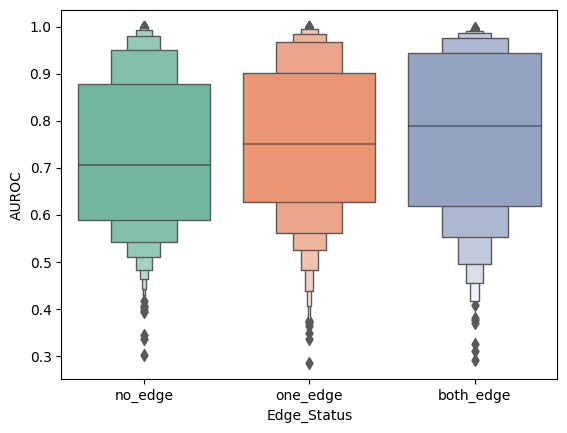

In [148]:
sns.boxenplot(data=class_res_df_batch.filter((~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(~pl.col("well_0_is_bg"))&(~pl.col("well_1_is_bg"))).to_pandas(), x="Edge_Status", y="AUROC", palette="Set2")

Edge Status categories: ['no_edge' 'one_edge' 'both_edge']
Number of categories: 3

no_edge:
  Sample size: 3374
  Mean: 0.7215
  Std: 0.1605
  Median: 0.6948

one_edge:
  Sample size: 1331
  Mean: 0.7450
  Std: 0.1644
  Median: 0.7280

both_edge:
  Sample size: 371
  Mean: 0.7546
  Std: 0.1810
  Median: 0.7684

=== ONE-WAY ANOVA RESULTS ===
F-statistic: 14.4375
p-value: 0.000001
Significant at α=0.05: Yes

=== PAIRWISE T-TESTS ===
no_edge vs one_edge:
  t-statistic: -4.4931
  p-value: 0.000007 ***
  Cohen's d: -0.1454
  Effect size: Small
  Mean difference: -0.0235
no_edge vs both_edge:
  t-statistic: -3.7225
  p-value: 0.000200 ***
  Cohen's d: -0.2036
  Effect size: Small
  Mean difference: -0.0331
one_edge vs both_edge:
  t-statistic: -0.9737
  p-value: 0.330350 
  Cohen's d: -0.0572
  Effect size: Small
  Mean difference: -0.0096

=== SUMMARY TABLE ===
           Comparison  p_value Significant Effect_Size Effect_Magnitude
  no_edge vs one_edge 0.000007         Yes     -0.1454    

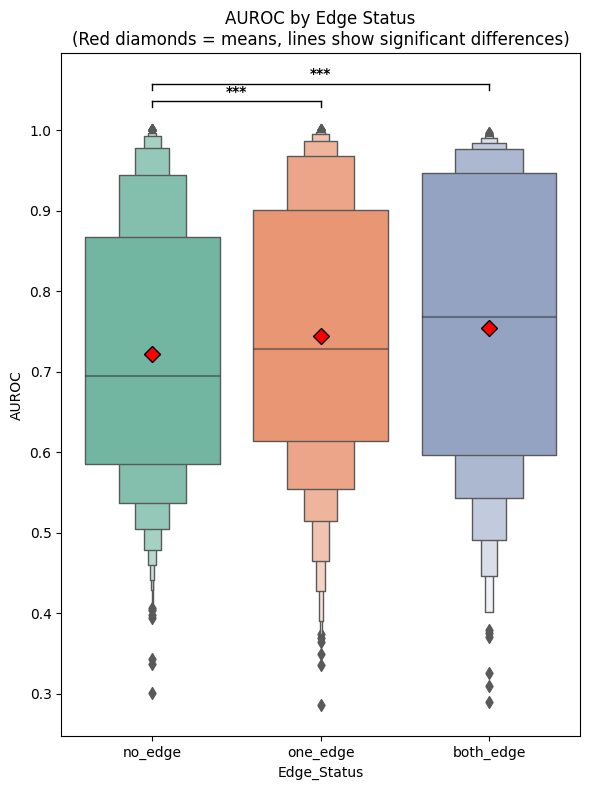


=== CONCLUSIONS ===


In [175]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import f_oneway
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

# Prepare the data
df_filtered_ = class_res_df_batch.filter(
    (~pl.col("Metadata_Control")) & 
    (pl.col("Metadata_Feature_Type") == "GFP") &
    (~pl.col("well_0_is_bg")) & 
    (~pl.col("well_1_is_bg"))
)

df_filtered = df_filtered_.to_pandas()

# # Create the boxenplot
# plt.figure(figsize=(10, 6))
# sns.boxenplot(data=df_filtered, x="Edge_Status", y="AUROC", palette="Set2")
# plt.title("AUROC by Edge Status")
# plt.show()

# Get unique Edge_Status categories
edge_statuses = df_filtered['Edge_Status'].unique()
print(f"Edge Status categories: {edge_statuses}")
print(f"Number of categories: {len(edge_statuses)}")

# Prepare data for ANOVA
groups_data = {}
for status in edge_statuses:
    group_data = df_filtered[df_filtered['Edge_Status'] == status]['AUROC'].dropna()
    groups_data[status] = group_data
    print(f"\n{status}:")
    print(f"  Sample size: {len(group_data)}")
    print(f"  Mean: {group_data.mean():.4f}")
    print(f"  Std: {group_data.std():.4f}")
    print(f"  Median: {group_data.median():.4f}")

# Perform one-way ANOVA
groups_for_anova = [groups_data[status].values for status in edge_statuses]
f_stat, p_value = f_oneway(*groups_for_anova)

print(f"\n=== ONE-WAY ANOVA RESULTS ===")
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value: {p_value:.6f}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")

# Perform pairwise t-tests
print(f"\n=== PAIRWISE T-TESTS ===")
pairwise_results = {}

for i, status1 in enumerate(edge_statuses):
    for j, status2 in enumerate(edge_statuses):
        if i < j:  # Avoid duplicate comparisons
            group1 = groups_data[status1]
            group2 = groups_data[status2]
            
            # Perform independent t-test
            t_stat, t_p_value = stats.ttest_ind(group1, group2)
            
            # Calculate effect size (Cohen's d)
            pooled_std = np.sqrt(((len(group1) - 1) * group1.var() + 
                                 (len(group2) - 1) * group2.var()) / 
                                (len(group1) + len(group2) - 2))
            cohens_d = (group1.mean() - group2.mean()) / pooled_std
            
            pairwise_results[f"{status1}_vs_{status2}"] = {
                't_stat': t_stat,
                'p_value': t_p_value,
                'cohens_d': cohens_d,
                'significant': t_p_value < 0.05
            }
            
            significance_marker = "***" if t_p_value < 0.001 else "**" if t_p_value < 0.01 else "*" if t_p_value < 0.05 else ""
            
            print(f"{status1} vs {status2}:")
            print(f"  t-statistic: {t_stat:.4f}")
            print(f"  p-value: {t_p_value:.6f} {significance_marker}")
            print(f"  Cohen's d: {cohens_d:.4f}")
            print(f"  Effect size: {'Small' if abs(cohens_d) < 0.5 else 'Medium' if abs(cohens_d) < 0.8 else 'Large'}")
            print(f"  Mean difference: {group1.mean() - group2.mean():.4f}")

# Summary table
print(f"\n=== SUMMARY TABLE ===")
summary_data = []
for comparison, result in pairwise_results.items():
    summary_data.append({
        'Comparison': comparison.replace('_vs_', ' vs '),
        'p_value': f"{result['p_value']:.6f}",
        'Significant': 'Yes' if result['significant'] else 'No',
        'Effect_Size': f"{result['cohens_d']:.4f}",
        'Effect_Magnitude': 'Small' if abs(result['cohens_d']) < 0.5 else 'Medium' if abs(result['cohens_d']) < 0.8 else 'Large'
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

# Create a more detailed visualization with significance annotations
plt.figure(figsize=(6, 8))
ax = sns.boxenplot(data=df_filtered, x="Edge_Status", y="AUROC", palette="Set2")

# Add mean markers
means = [groups_data[status].mean() for status in edge_statuses]
for i, mean_val in enumerate(means):
    ax.plot(i, mean_val, marker='D', color='red', markersize=8, markeredgecolor='black')

# Add significance annotations above the plot
y_max = df_filtered['AUROC'].max()
y_range = df_filtered['AUROC'].max() - df_filtered['AUROC'].min()

# Add statistical significance annotations
height_offset = 0.05
for i, (comparison, result) in enumerate(pairwise_results.items()):
    if result['significant']:
        # Extract the two categories being compared
        cat1, cat2 = comparison.split('_vs_')
        pos1 = list(edge_statuses).index(cat1)
        pos2 = list(edge_statuses).index(cat2)
        y_pos = y_max + y_range * (height_offset + i * 0.03)
        # Draw line
        ax.plot([pos1, pos2], [y_pos, y_pos], 'k-', linewidth=1)
        ax.plot([pos1, pos1], [y_pos - y_range * 0.01, y_pos], 'k-', linewidth=1)
        ax.plot([pos2, pos2], [y_pos - y_range * 0.01, y_pos], 'k-', linewidth=1)
        
        # Add significance marker
        significance = "***" if result['p_value'] < 0.001 else "**" if result['p_value'] < 0.01 else "*"
        ax.text((pos1 + pos2) / 2, y_pos + y_range * 0.005, significance, 
                ha='center', va='bottom', fontweight='bold')

plt.title("AUROC by Edge Status\n(Red diamonds = means, lines show significant differences)")
plt.ylabel("AUROC")
plt.tight_layout()
plt.show()
# Overall conclusion
print(f"\n=== CONCLUSIONS ===")
# if p_value < 0.05:
#     significant_pairs = [comp for comp, result in pairwise_results.items() if result['significant']]
#     print(f"Overall ANOVA is significant (p = {p_value:.6f})")
#     print(f"Number of significant pairwise comparisons: {len(significant_pairs)}")
#     if significant_pairs:
#         print("Significant pairwise differences found between:")
#         for pair in significant_pairs:
#             print(f"  - {pair.replace('_vs_', ' vs ')}")
# else:
#     print(f"Overall ANOVA is not significant (p = {p_value:.6f})")
#     print("No strong evidence for differences between Edge Status groups")

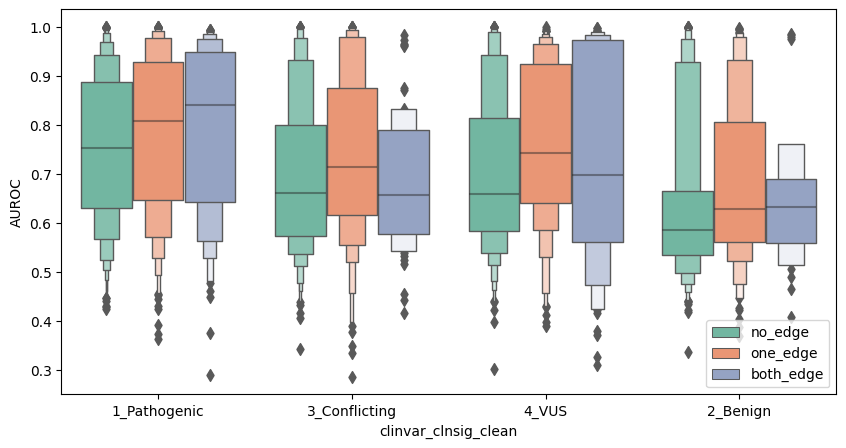

In [176]:
df_filtered_ = df_filtered_.join(
    clin_var_info,
    on="allele_0"
)

fig, ax = plt.subplots(1,1,figsize=(10,5))
sns.boxenplot(data=df_filtered_.drop_nulls(
    pl.col("clinvar_clnsig_clean")
).filter(
    (~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(pl.col("clinvar_clnsig_clean")!="5_Others")
).to_pandas(), x="clinvar_clnsig_clean", hue="Edge_Status", y="AUROC", ax=ax, 
              order=["1_Pathogenic","3_Conflicting","4_VUS","2_Benign"],palette="Set2")
ax.legend(loc="lower right")

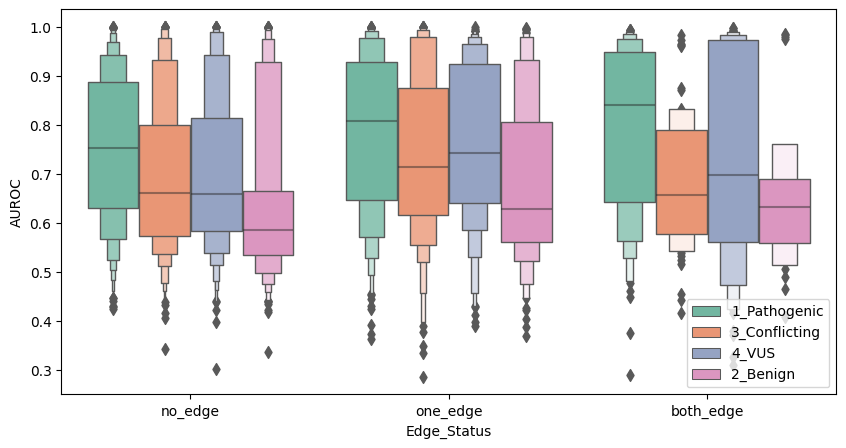

In [166]:
fig, ax = plt.subplots(1,1,figsize=(10,5))
sns.boxenplot(data=df_filtered_.drop_nulls(
    pl.col("clinvar_clnsig_clean")
).filter(
    (~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(pl.col("clinvar_clnsig_clean")!="5_Others")
).to_pandas(), x="Edge_Status", hue="clinvar_clnsig_clean", y="AUROC", ax=ax, 
              hue_order=["1_Pathogenic","3_Conflicting","4_VUS","2_Benign"],palette="Set2")
ax.legend(loc="lower right")

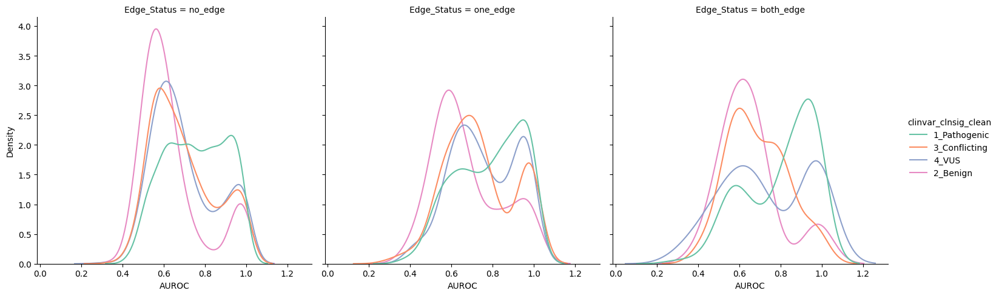

In [177]:
# fig, ax = plt.subplots(1,1,figsize=(10,5))
sns.displot(data=df_filtered_.drop_nulls(
    pl.col("clinvar_clnsig_clean")
).filter(
    (~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(pl.col("clinvar_clnsig_clean")!="5_Others")
).to_pandas(), x="AUROC", hue="clinvar_clnsig_clean", col="Edge_Status", kind="kde", common_norm=False,
              hue_order=["1_Pathogenic","3_Conflicting","4_VUS","2_Benign"], palette="Set2")
# ax.legend(loc="lower right")

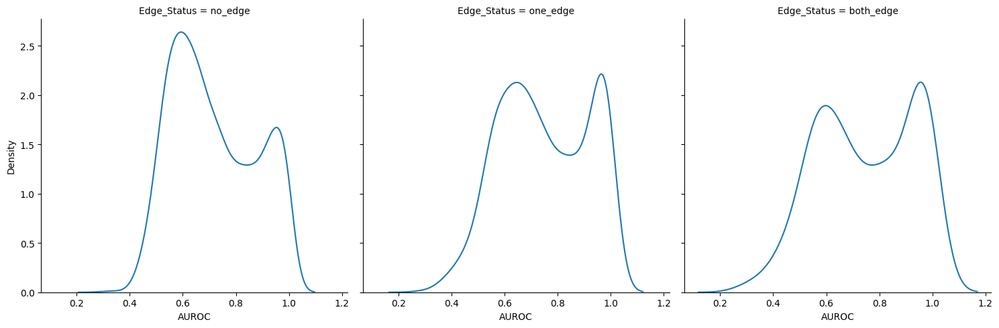

In [178]:
sns.displot(data=df_filtered_.drop_nulls(
    pl.col("clinvar_clnsig_clean")
).filter(
    (~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(pl.col("clinvar_clnsig_clean")!="5_Others")
).to_pandas(), x="AUROC", col="Edge_Status", kind="kde", common_norm=False,
              hue_order=["1_Pathogenic","3_Conflicting","4_VUS","2_Benign"], palette="Set2")
# ax.legend(loc="lower right")

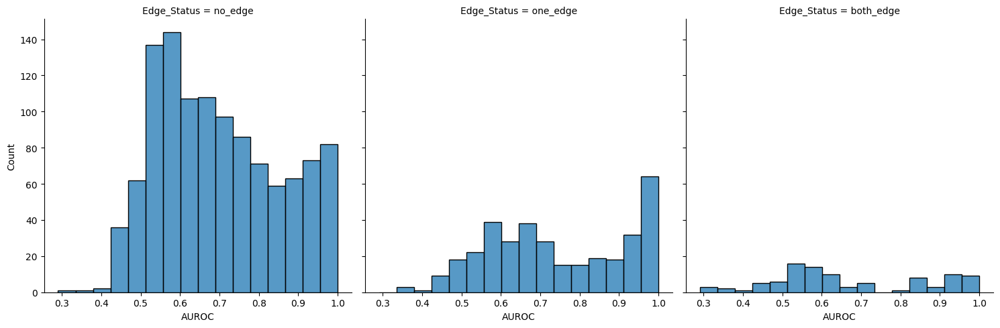

In [184]:
sns.displot(data=df_filtered_.drop_nulls(
    pl.col("clinvar_clnsig_clean")
).filter(
    (~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(pl.col("clinvar_clnsig_clean")!="5_Others")&(pl.col("Full_Classifier_ID").str.contains("B8"))
).to_pandas(), x="AUROC", col="Edge_Status", kind="hist", common_norm=False,
              hue_order=["1_Pathogenic","3_Conflicting","4_VUS","2_Benign"], palette="Set2")

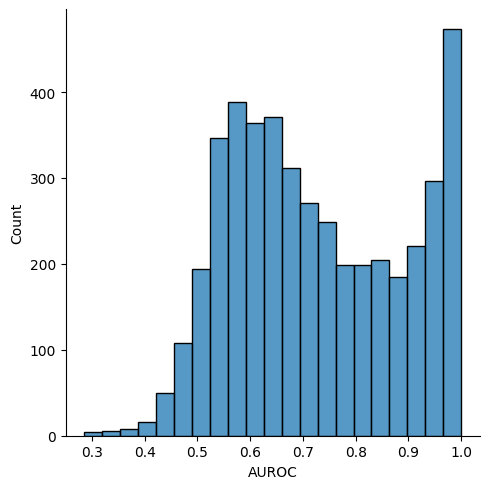

In [182]:
sns.displot(data=df_filtered_.drop_nulls(
    pl.col("clinvar_clnsig_clean")
).filter(
    (~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP")&(pl.col("clinvar_clnsig_clean")!="5_Others")
).to_pandas(), x="AUROC", kind="hist", common_norm=False,
              hue_order=["1_Pathogenic","3_Conflicting","4_VUS","2_Benign"], palette="Set2")

In [116]:
# # fig, ax = plt.subplots(1,1,figsize=(10,5))
# sns.displot(data=class_res_df_batch.drop_nulls(
#     pl.col("clinvar_clnsig_clean")
# ).filter(
#     (~pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="Morph")&(pl.col("clinvar_clnsig_clean")!="5_Others")
# ).to_pandas(), x="AUROC", hue="clinvar_clnsig_clean", col="Edge_Status", kind="kde", common_norm=False,
#               hue_order=["1_Pathogenic","3_Conflicting","4_VUS","2_Benign"], palette="Set2")
# # ax.legend(loc="lower right")

In [35]:
BATCH_DICTS_2 = {
    "2024_12_Batch_11-12": ["2024_12_09_Batch_11", "2024_12_09_Batch_12"]
}
class_res_df_batch_3 = pl.DataFrame()

for combined_bio_rep, bio_rep_batches in BATCH_DICTS_2.items():
    img_qc_dir = f"../../../8.3_downstream_analysis_runxi/outputs/{combined_bio_rep}"
    img_well_qc_sum = pl.read_csv(f"{img_qc_dir}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")

    for batch_id in bio_rep_batches:
        class_res_df = pl.read_csv(class_info_dir.format(CLASS_RES_DIR, batch_id))
        # Define your edge‐detecting regex once
        edge_regex = r"(?:01|P|A|24)"
        # Now create a new column “Edge_Status” with three cases:
        #  • “both_edge” if both well_0 and well_1 match the regex
        #  • “one_edge”  if exactly one of them matches
        #  • “no_edge”   otherwise
        class_res_df = class_res_df.with_columns([
            pl.when(
                (pl.col("well_0").str.contains(edge_regex)) & 
                (pl.col("well_1").str.contains(edge_regex))
            )
            .then(pl.lit("both_edge"))
            .when(
                (pl.col("well_0").str.contains(edge_regex)) | 
                (pl.col("well_1").str.contains(edge_regex))
            )
            .then(pl.lit("one_edge"))
            .otherwise(pl.lit("no_edge"))
            .alias("Edge_Status"),
            pl.when(pl.col("Full_Classifier_ID").str.contains("true"))
            .then(pl.lit("GFP"))
            .otherwise(pl.lit("Morph"))
            .alias("Metadata_Feature_Type")
        ])
        # display(class_res_df.filter(pl.col("Edge_Status")=="both_edge"))
        # display(img_well_qc_sum)
        
        for channel in ["GFP", "Morph"]:
            class_res_df_channel = class_res_df.filter(pl.col("Metadata_Feature_Type")==channel)
            class_res_df_channel = class_res_df_channel.join(
                img_well_qc_sum.filter(pl.col("channel")==channel).select(pl.col(["plate","well","is_bg"])),
                left_on=["Plate","well_0"],
                right_on=["plate","well"]
            ).rename({"is_bg": "well_0_is_bg"})
            class_res_df_channel = class_res_df_channel.join(
                img_well_qc_sum.filter(pl.col("channel")==channel).select(pl.col(["plate","well","is_bg"])),
                left_on=["Plate","well_1"],
                right_on=["plate","well"]
            ).rename({"is_bg": "well_1_is_bg"})
            class_res_df_batch_3 = pl.concat([class_res_df_batch_3, class_res_df_channel])
            
            # print(class_res_df_channel["Plate"].unique())
            # plate_maps = sorted(set([pm.split("T")[0] for pm in class_res_df_channel["Plate"].unique()]))
            # for pm in plate_maps:
            #     # print(pm)
            #     class_res_ch_pm = class_res_df_channel.filter(pl.col("Plate").str.contains(pm))
            #     plates = sorted(class_res_ch_pm["Plate"].unique().to_list())
            #     fig, axes = plt.subplots(2,2,figsize=(48,23)) ## sharey=True,sharex=True
            #     for plate in plates:
            #         plate_info = class_res_ch_pm.filter(pl.col("Plate")==plate)
            #         ## plot the ctrls alleles first
            #         # plate_info_ctrl = plate_info.filter(pl.col("Metadata_Control"))
            #         # ctrls_wells = pl.concat([plate_info_ctrl["well_0"], plate_info_ctrl["well_1"]]).unique()
            #         # agg_group_by_well_0 = plate_info_ctrl.group_by("well_0","allele_0").agg([
            #         #     pl.col("AUROC").mean().alias("AUROC_Mean"),
            #         #     pl.col("well_0_is_bg").max().alias("is_bg")
            #         # ]).rename(
            #         #     {"well_0": "well", "allele_0": "allele"}
            #         # )#.with_columns(pl.col("Well_On_Edge").cast(pl.Boolean).alias("Well_On_Edge"))
            #         # agg_group_by_well_1 = plate_info_ctrl.filter(
            #         #     (pl.col("well_1").is_in(ctrls_wells))&\
            #         #     (~pl.col("well_1").is_in(agg_group_by_well_0["well"]))
            #         # ).group_by("well_1","allele_1").agg([
            #         #     pl.col("AUROC").mean().alias("AUROC_Mean"),
            #         #     pl.col("well_1_is_bg").max().alias("is_bg")
            #         # ]).rename(
            #         #     {"well_1": "well", "allele_1": "allele"}
            #         # )
            #         # agg_group_by_well_ctrl = pl.concat(
            #         #     [
            #         #         agg_group_by_well_0.select(pl.col("well","AUROC_Mean","allele","is_bg")),
            #         #         agg_group_by_well_1.select(pl.col("well","AUROC_Mean","allele","is_bg"))
            #         #     ]
            #         # )
            #         # ## plot the auroc per each plate for a platemap
            #         # plot_platemap(
            #         #     agg_group_by_well,
            #         #     plate+f"_{channel}",
            #         #     well_pos_col="well",
            #         #     # this is the column to color by (categorical or continuous)
            #         #     value_col="AUROC_Mean",
            #         #     # these columns will be concatenated into the annotation text
            #         #     label_cols=("allele","AUROC_Mean"),
            #         #     ax=axes[plates.index(plate)//2, plates.index(plate)%2],
            #         #     value_type="continuous",   # or "continuous"
            #         #     continuous_cmap="vlag",  # matplotlib colormap for continuous mode
            #         #     categorical_colors={True: "tomato", False: "skyblue"},     # dict for categorical → color
            #         #     grid_square="is_bg"
            #         # )
            #         ## plot the variant alleles
            #         plate_info_var_wt = plate_info.filter(~pl.col("Metadata_Control"))
            #         agg_group_by_var_well = plate_info_var_wt.group_by("well_0","allele_0").agg([
            #             pl.col("AUROC").mean().alias("AUROC_Mean"),
            #             pl.col("well_0_is_bg").max().alias("well0_is_bg"),
            #             pl.col("well_1_is_bg").max().alias("well1_is_bg")
            #         ]).rename(
            #             {"well_0": "well", "allele_0": "allele"}
            #         ).with_columns(
            #             pl.max_horizontal(["well0_is_bg", "well1_is_bg"]).alias("is_bg"),
            #             # pl.col("Well_On_Edge").cast(pl.Boolean).alias("Well_On_Edge"))
            #         )
            #         ## plot the auroc per each plate for a platemap
            #         plot_platemap(
            #             agg_group_by_var_well,
            #             plate+f"_{channel}",
            #             well_pos_col="well",
            #             # this is the column to color by (categorical or continuous)
            #             value_col="AUROC_Mean",
            #             # these columns will be concatenated into the annotation text
            #             label_cols=("allele","AUROC_Mean"),
            #             ax=axes[plates.index(plate)//2, plates.index(plate)%2],
            #             value_type="continuous",   # or "continuous"
            #             continuous_cmap="vlag",  # matplotlib colormap for continuous mode
            #             categorical_colors={True: "tomato", False: "skyblue"},     # dict for categorical → color
            #             grid_square="is_bg"
            #         )
            #     fig.subplots_adjust(wspace=-.55, hspace=.05)
            #     plt.tight_layout()

[Text(0, 0, 'MLH1_Lys618Arg-MLH1'),
 Text(1, 0, 'MLH1_Asp41His-MLH1'),
 Text(2, 0, 'MLH1_Gly147Arg-MLH1'),
 Text(3, 0, 'MLH1_Ala160Val-MLH1'),
 Text(4, 0, 'MLH1_Gly244Asp-MLH1'),
 Text(5, 0, 'MLH1_Cys680Arg-MLH1'),
 Text(6, 0, 'STXBP1_Arg551Leu-STXBP1'),
 Text(7, 0, 'STXBP1_Gly417Asp-STXBP1'),
 Text(8, 0, 'MLH1_Ala681Val-MLH1'),
 Text(9, 0, 'MLH1_Leu653Pro-MLH1'),
 Text(10, 0, 'MLH1_Cys39Tyr-MLH1'),
 Text(11, 0, 'MLH1_Lys751Arg-MLH1'),
 Text(12, 0, 'MLH1_Asn38Lys-MLH1'),
 Text(13, 0, 'MLH1_Val185Gly-MLH1'),
 Text(14, 0, 'STXBP1_Lys333Glu-STXBP1'),
 Text(15, 0, 'MLH1_Ala681Thr-MLH1'),
 Text(16, 0, 'STXBP1_Arg190Trp-STXBP1'),
 Text(17, 0, 'MVK_Leu265Pro-MVK'),
 Text(18, 0, 'MLH1_Ser44Phe-MLH1'),
 Text(19, 0, 'MLH1_Gln701His-MLH1'),
 Text(20, 0, 'MLH1_Ser295Thr-MLH1'),
 Text(21, 0, 'MLH1_Ala586Asp-MLH1'),
 Text(22, 0, 'MLH1_Ala29Gly-MLH1'),
 Text(23, 0, 'GSS_Arg125Cys-GSS'),
 Text(24, 0, 'MLH1_Pro747Ser-MLH1'),
 Text(25, 0, 'MLH1_Leu582Val-MLH1'),
 Text(26, 0, 'MLH1_Pro640Ser-MLH1'),
 Tex

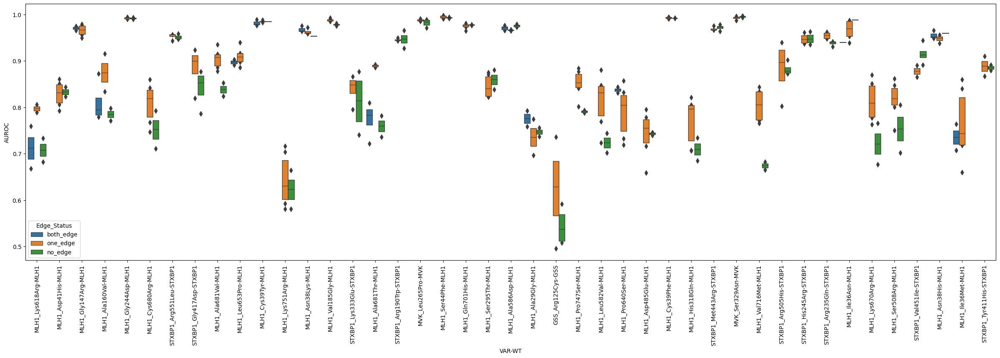

In [46]:
df = class_res_df_batch_3.filter(
    (~pl.col("Metadata_Control")) &
    (pl.col("Metadata_Feature_Type") == "GFP")
).with_columns(
    # 1) build the VAR-WT key
    pl.concat_str([pl.col("allele_0"), pl.col("allele_1")], separator="-")
      .alias("VAR-WT")
)

# 2) compute, for each row, how many distinct Edge_status exist in its VAR-WT group
df = df.with_columns([
    pl.col("Edge_Status")
      .n_unique()
      .over("VAR-WT")
      .alias("n_unique_edge")
])

# 3) keep only the rows whose VAR-WT has more than one Edge_status
result = df.filter(pl.col("n_unique_edge") > 1)

fig, ax = plt.subplots(1, 1, figsize=(30, 8))
sns.boxenplot(data=result.to_pandas(), x="VAR-WT", y="AUROC", hue="Edge_Status", ax=ax, dodge=True)
labels = ax.get_xticklabels()
ax.set_xticklabels(labels, rotation=90)

Number of VAR-WT groups with significant differences: 7
Total VAR-WT groups analyzed: 43


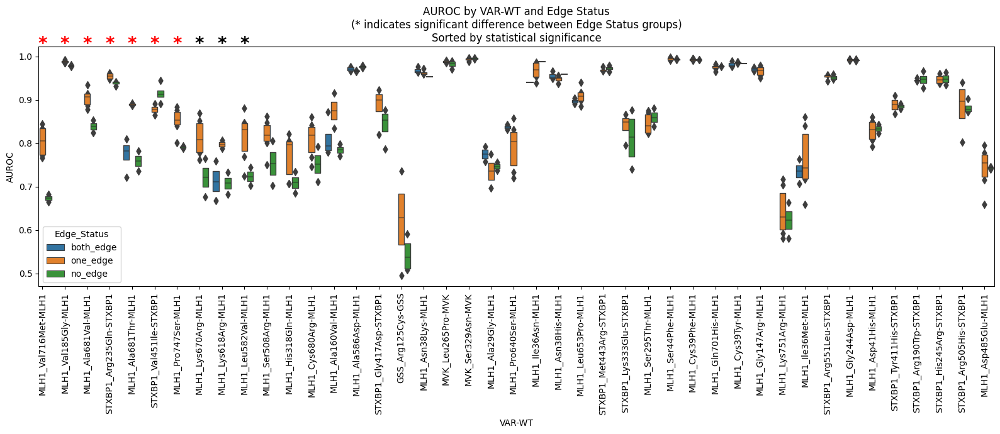

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import f_oneway
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

# Your existing data preparation code
df = class_res_df_batch_3.filter(
    (~pl.col("Metadata_Control")) &
    (pl.col("Metadata_Feature_Type") == "GFP")
).with_columns(
    # 1) build the VAR-WT key
    pl.concat_str([pl.col("allele_0"), pl.col("allele_1")], separator="-")
      .alias("VAR-WT")
)

# 2) compute, for each row, how many distinct Edge_status exist in its VAR-WT group
df = df.with_columns([
    pl.col("Edge_Status")
      .n_unique()
      .over("VAR-WT")
      .alias("n_unique_edge")
])

# 3) keep only the rows whose VAR-WT has more than one Edge_status
result = df.filter(pl.col("n_unique_edge") > 1)

# Convert to pandas for easier statistical analysis
result_pd = result.to_pandas()

def perform_anova_analysis(data, alpha=0.05):
    """
    Perform ANOVA analysis for each VAR-WT group and identify significant differences
    
    Parameters:
    data: pandas DataFrame
    alpha: significance level (default 0.05)
    
    Returns:
    Dictionary with VAR-WT groups as keys and significance info as values
    """
    
    results = {}
    var_wt_groups = data['VAR-WT'].unique()
    
    for var_wt in var_wt_groups:
        group_data = data[data['VAR-WT'] == var_wt]
        edge_statuses = group_data['Edge_Status'].unique()
        
        # Skip if only one Edge_Status (shouldn't happen based on filtering, but safety check)
        if len(edge_statuses) < 2:
            results[var_wt] = {
                'significant': False,
                'p_value': None,
                'edge_statuses': edge_statuses,
                'sample_sizes': {},
                'means': {},
                'pairwise_results': {}
            }
            continue
        
        # Prepare data for ANOVA
        groups_for_anova = []
        sample_sizes = {}
        means = {}
        
        for status in edge_statuses:
            status_data = group_data[group_data['Edge_Status'] == status]['AUROC'].dropna()
            groups_for_anova.append(status_data.values)
            sample_sizes[status] = len(status_data)
            means[status] = status_data.mean()
        
        # Perform one-way ANOVA
        try:
            if len(groups_for_anova) >= 2 and all(len(group) > 0 for group in groups_for_anova):
                f_stat, p_value = f_oneway(*groups_for_anova)
                
                # Perform pairwise t-tests if ANOVA is significant
                pairwise_results = {}
                if p_value < alpha:
                    for i, status1 in enumerate(edge_statuses):
                        for j, status2 in enumerate(edge_statuses):
                            if i < j:  # Avoid duplicate comparisons
                                group1 = group_data[group_data['Edge_Status'] == status1]['AUROC'].dropna()
                                group2 = group_data[group_data['Edge_Status'] == status2]['AUROC'].dropna()
                                
                                if len(group1) > 0 and len(group2) > 0:
                                    t_stat, t_p_value = stats.ttest_ind(group1, group2)
                                    pairwise_results[f"{status1}_vs_{status2}"] = {
                                        't_stat': t_stat,
                                        'p_value': t_p_value,
                                        'significant': t_p_value < alpha
                                    }
                
                results[var_wt] = {
                    'significant': p_value < alpha,
                    'p_value': p_value,
                    'f_stat': f_stat,
                    'edge_statuses': edge_statuses,
                    'sample_sizes': sample_sizes,
                    'means': means,
                    'pairwise_results': pairwise_results
                }
            else:
                results[var_wt] = {
                    'significant': False,
                    'p_value': None,
                    'edge_statuses': edge_statuses,
                    'sample_sizes': sample_sizes,
                    'means': means,
                    'pairwise_results': {}
                }
        except Exception as e:
            print(f"Error analyzing {var_wt}: {e}")
            results[var_wt] = {
                'significant': False,
                'p_value': None,
                'edge_statuses': edge_statuses,
                'sample_sizes': {},
                'means': {},
                'pairwise_results': {}
            }
    
    return results

# Perform the analysis
anova_results = perform_anova_analysis(result_pd)

# Create a summary of significant results
significant_groups = [var_wt for var_wt, result in anova_results.items() if result['significant']]
print(f"Number of VAR-WT groups with significant differences: {len(significant_groups)}")
print(f"Total VAR-WT groups analyzed: {len(anova_results)}")

# # Print detailed results for significant groups
# print("\n=== SIGNIFICANT GROUPS ===")
# for var_wt in significant_groups:
#     result = anova_results[var_wt]
#     print(f"\n{var_wt}:")
#     print(f"  ANOVA p-value: {result['p_value']:.6f}")
#     print(f"  Edge statuses: {result['edge_statuses']}")
#     print(f"  Sample sizes: {result['sample_sizes']}")
#     print(f"  Means: {result['means']}")
    
#     if result['pairwise_results']:
#         print("  Pairwise comparisons:")
#         for comparison, pairwise in result['pairwise_results'].items():
#             significance_marker = "***" if pairwise['significant'] else ""
#             print(f"    {comparison}: p = {pairwise['p_value']:.6f} {significance_marker}")

# Sort VAR-WT groups by significance (significant first, then by p-value)
def get_sort_key(var_wt):
    result = anova_results[var_wt]
    if result['significant']:
        # For significant groups, sort by p-value (ascending)
        return (0, result['p_value'] if result['p_value'] is not None else 1)
    else:
        # For non-significant groups, sort by p-value (ascending) after significant groups
        return (1, result['p_value'] if result['p_value'] is not None else 1)

sorted_var_wt = sorted(anova_results.keys(), key=get_sort_key)

# Create ordered categorical for proper sorting in the plot
result_pd['VAR-WT'] = pd.Categorical(result_pd['VAR-WT'], categories=sorted_var_wt, ordered=True)

## Create a summary table (sorted by significance)
summary_data = []
for var_wt in sorted_var_wt:  # Use sorted order
    result = anova_results[var_wt]
    summary_data.append({
        'VAR-WT': var_wt,
        'Significant': result['significant'],
        'ANOVA_p_value': result['p_value'],
        'Edge_Statuses': ', '.join(result['edge_statuses']) if result['edge_statuses'] is not None else '',
        'Sample_Sizes': str(result['sample_sizes']),
        'Means': str({k: f"{v:.4f}" for k, v in result['means'].items()}) if result['means'] else ''
    })

summary_df = pd.DataFrame(summary_data)

# Create the plot with significance markers
fig, ax = plt.subplots(1, 1, figsize=(16,7))
sns.boxenplot(data=result_pd, x="VAR-WT", y="AUROC", hue="Edge_Status", ax=ax, dodge=True, width=0.8)

# Reduce gaps between VAR-WT groups but add spacing within groups
ax.margins(x=0.001)  # Reduce horizontal margins to decrease gaps between VAR-WT groups

# Increase spacing between hue categories within each VAR-WT group
# This is done by adjusting the dodge parameter and box positions
for i, artist in enumerate(ax.patches):
    # Get the current position
    x = artist.get_x()
    width = artist.get_width()
    
    # Slightly increase the width of each box
    artist.set_width(width * 1.2)
    
    # Adjust spacing within groups by modifying x position slightly
    # This creates small gaps between different Edge_Status within same VAR-WT
    if hasattr(artist, 'get_facecolor'):  # Safety check
        artist.set_x(x - width * 0.1)

# Add asterisks above the boxplots for significant groups
y_max = result_pd['AUROC'].max()
y_range = result_pd['AUROC'].max() - result_pd['AUROC'].min()
star_height = y_max + y_range * 0.02  # Position stars slightly above the highest values

# Get x-axis positions for each VAR-WT group
x_positions = range(len(sorted_var_wt))

for i, var_wt in enumerate(sorted_var_wt):
    if var_wt in significant_groups:
        # Add star above the boxplot
        ax.text(i, star_height, '*', ha='center', va='bottom', 
                fontsize=20, fontweight='bold', color='red')
    if var_wt in summary_df[(summary_df["ANOVA_p_value"]>0.05)&(summary_df["ANOVA_p_value"]<0.1)]["VAR-WT"].unique():
        ax.text(i, star_height, '*', ha='center', va='bottom', 
                fontsize=20, fontweight='bold', color='black')

# Set x-tick labels without asterisks (since we're adding them above)
ax.set_xticklabels(sorted_var_wt, rotation=90)
ax.set_title("AUROC by VAR-WT and Edge Status\n(* indicates significant difference between Edge Status groups)\nSorted by statistical significance")

# Adjust y-axis limits to accommodate stars
ax.set_ylim(ax.get_ylim()[0], star_height + y_range * 0.03)

plt.tight_layout()
plt.show()
# print("\n=== SUMMARY TABLE ===")
# print(summary_df.to_string(index=False))

# Save detailed results to CSV if needed
# summary_df.to_csv('anova_results_summary.csv', index=False)

# # Additional statistics
# print(f"\n=== OVERALL STATISTICS ===")
# print(f"Proportion of significant groups: {len(significant_groups)/len(anova_results):.3f}")
# print(f"Groups with 2 Edge_Status categories: {sum(1 for r in anova_results.values() if len(r['edge_statuses']) == 2)}")
# print(f"Groups with 3+ Edge_Status categories: {sum(1 for r in anova_results.values() if len(r['edge_statuses']) >= 3)}")

In [79]:
9/43

0.20930232558139536

In [113]:
class_res_df_batch_3.filter((pl.col("allele_0")=="MLH1_Ala681Val")&(pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP"))

AUROC,AUPRC,AUBPRC,Macro_F1,Sensitivity,Specificity,Balanced_Accuracy,Classifier_ID,Full_Classifier_ID,Plate,trainsize_0,testsize_0,well_0,allele_0,trainsize_1,testsize_1,well_1,allele_1,Metadata_Control,train_prob_1,test_prob_1,Training_imbalance,Testing_imbalance,Edge_Status,Metadata_Feature_Type,well_0_is_bg,well_1_is_bg
f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,i64,str,str,i64,i64,str,str,bool,f64,f64,f64,f64,str,str,bool,bool
0.497254,0.528741,0.51068,0.491487,0.5637,0.422139,0.492919,"""2024-12-09_B11A1R1_D04_D03""","""2024-12-09_B11A1R1_D04_D03_tru…","""2024-12-09_B11A1R1""",844,1066,"""D04""","""MLH1_Ala681Val""",1054,1146,"""D03""","""MLH1_Ala681Val""",true,0.555321,0.518083,1.248815,1.075047,"""no_edge""","""GFP""",false,false
0.481415,0.472538,0.493432,0.491733,0.418406,0.568063,0.493234,"""2024-12-09_B11A1R1_D03_C03""","""2024-12-09_B11A1R1_D03_C03_tru…","""2024-12-09_B11A1R1""",1066,1146,"""D03""","""MLH1_Ala681Val""",844,1054,"""C03""","""MLH1_Ala681Val""",true,0.441885,0.479091,1.263033,1.087287,"""no_edge""","""GFP""",false,false
0.477144,0.491076,0.493906,0.484853,0.395636,0.582552,0.489094,"""2024-12-09_B11A1R1_D04_C03""","""2024-12-09_B11A1R1_D04_C03_tru…","""2024-12-09_B11A1R1""",1146,1066,"""D04""","""MLH1_Ala681Val""",844,1054,"""C03""","""MLH1_Ala681Val""",true,0.424121,0.49717,1.35782,1.011385,"""no_edge""","""GFP""",false,false
0.494269,0.418223,0.493952,0.496357,0.462085,0.532286,0.497186,"""2024-12-09_B11A1R1_D03_C04""","""2024-12-09_B11A1R1_D03_C04_tru…","""2024-12-09_B11A1R1""",1066,1146,"""D03""","""MLH1_Ala681Val""",1054,844,"""C04""","""MLH1_Ala681Val""",true,0.49717,0.424121,1.011385,1.35782,"""no_edge""","""GFP""",false,false
0.516632,0.572178,0.51713,0.500302,0.497154,0.507109,0.502131,"""2024-12-09_B11A1R1_C04_C03""","""2024-12-09_B11A1R1_C04_C03_tru…","""2024-12-09_B11A1R1""",1066,844,"""C04""","""MLH1_Ala681Val""",1146,1054,"""C03""","""MLH1_Ala681Val""",true,0.518083,0.555321,1.075047,1.248815,"""no_edge""","""GFP""",false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.520558,0.549585,0.512066,0.520392,0.578792,0.462329,0.520561,"""2024-12-09_B12A1R2_D04_D03""","""2024-12-09_B12A1R2_D04_D03_tru…","""2024-12-09_B12A1R2""",585,584,"""D04""","""MLH1_Ala681Val""",694,679,"""D03""","""MLH1_Ala681Val""",true,0.542611,0.537609,1.186325,1.162671,"""no_edge""","""GFP""",false,false
0.440877,0.41405,0.450602,0.450981,0.528205,0.385862,0.457033,"""2024-12-09_B12A1R2_D03_C04""","""2024-12-09_B12A1R2_D03_C04_tru…","""2024-12-09_B12A1R2""",584,679,"""D03""","""MLH1_Ala681Val""",694,585,"""C04""","""MLH1_Ala681Val""",true,0.543036,0.462816,1.188356,1.160684,"""no_edge""","""GFP""",false,false
0.502177,0.54358,0.500976,0.488178,0.554755,0.422222,0.488489,"""2024-12-09_B12A1R2_C04_C03""","""2024-12-09_B12A1R2_C04_C03_tru…","""2024-12-09_B12A1R2""",584,585,"""C04""","""MLH1_Ala681Val""",679,694,"""C03""","""MLH1_Ala681Val""",true,0.537609,0.542611,1.162671,1.186325,"""no_edge""","""GFP""",false,false


In [112]:
class_res_df_batch_3.filter((pl.col("allele_0")=="MLH1_Val185Gly")&(pl.col("Metadata_Control"))&(pl.col("Metadata_Feature_Type")=="GFP"))

AUROC,AUPRC,AUBPRC,Macro_F1,Sensitivity,Specificity,Balanced_Accuracy,Classifier_ID,Full_Classifier_ID,Plate,trainsize_0,testsize_0,well_0,allele_0,trainsize_1,testsize_1,well_1,allele_1,Metadata_Control,train_prob_1,test_prob_1,Training_imbalance,Testing_imbalance,Edge_Status,Metadata_Feature_Type,well_0_is_bg,well_1_is_bg
f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,i64,str,str,i64,i64,str,str,bool,f64,f64,f64,f64,str,str,bool,bool
0.579621,0.642721,0.581928,0.5463,0.511283,0.592479,0.551881,"""2024-12-09_B11A1R1_F07_E08""","""2024-12-09_B11A1R1_F07_E08_tru…","""2024-12-09_B11A1R1""",1748,1303,"""F07""","""MLH1_Val185Gly""",1663,1684,"""E08""","""MLH1_Val185Gly""",true,0.48754,0.563776,1.051112,1.292402,"""no_edge""","""GFP""",false,false
0.518996,0.526865,0.536152,0.489916,0.635392,0.365561,0.500476,"""2024-12-09_B11A1R1_F08_E08""","""2024-12-09_B11A1R1_F08_E08_tru…","""2024-12-09_B11A1R1""",1303,1748,"""F08""","""MLH1_Val185Gly""",1663,1684,"""E08""","""MLH1_Val185Gly""",true,0.560688,0.490676,1.276285,1.038005,"""no_edge""","""GFP""",false,false
0.459003,0.464345,0.467468,0.442053,0.25917,0.671021,0.465096,"""2024-12-09_B11A1R1_E08_E07""","""2024-12-09_B11A1R1_E08_E07_tru…","""2024-12-09_B11A1R1""",1748,1684,"""E08""","""MLH1_Val185Gly""",1303,1663,"""E07""","""MLH1_Val185Gly""",true,0.427073,0.496863,1.34152,1.012628,"""no_edge""","""GFP""",false,false
0.52107,0.593698,0.533779,0.514992,0.50451,0.531082,0.517796,"""2024-12-09_B11A1R1_F07_E07""","""2024-12-09_B11A1R1_F07_E07_tru…","""2024-12-09_B11A1R1""",1748,1303,"""F07""","""MLH1_Val185Gly""",1684,1663,"""E07""","""MLH1_Val185Gly""",true,0.490676,0.560688,1.038005,1.276285,"""no_edge""","""GFP""",false,false
0.420957,0.378623,0.449771,0.436143,0.405986,0.467391,0.436689,"""2024-12-09_B11A1R1_F08_F07""","""2024-12-09_B11A1R1_F08_F07_tru…","""2024-12-09_B11A1R1""",1684,1748,"""F08""","""MLH1_Val185Gly""",1663,1303,"""F07""","""MLH1_Val185Gly""",true,0.496863,0.427073,1.012628,1.34152,"""no_edge""","""GFP""",false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.475885,0.477746,0.487726,0.473862,0.396117,0.556903,0.47651,"""2024-12-09_B12A1R2_F08_F07""","""2024-12-09_B12A1R2_F08_F07_tru…","""2024-12-09_B12A1R2""",1076,1072,"""F08""","""MLH1_Val185Gly""",1031,1030,"""F07""","""MLH1_Val185Gly""",true,0.489321,0.49001,1.043647,1.040777,"""no_edge""","""GFP""",false,false
0.545253,0.544766,0.533911,0.526805,0.477695,0.579612,0.528653,"""2024-12-09_B12A1R2_F07_E08""","""2024-12-09_B12A1R2_F07_E08_tru…","""2024-12-09_B12A1R2""",1072,1030,"""F07""","""MLH1_Val185Gly""",1031,1076,"""E08""","""MLH1_Val185Gly""",true,0.490252,0.510921,1.039767,1.04466,"""no_edge""","""GFP""",false,false
0.545107,0.532817,0.532576,0.534182,0.541222,0.527184,0.534203,"""2024-12-09_B12A1R2_F07_E07""","""2024-12-09_B12A1R2_F07_E07_tru…","""2024-12-09_B12A1R2""",1072,1030,"""F07""","""MLH1_Val185Gly""",1076,1031,"""E07""","""MLH1_Val185Gly""",true,0.500931,0.500243,1.003731,1.000971,"""no_edge""","""GFP""",false,false


In [114]:
df.filter((pl.col("allele_0")=="MLH1_Val716Met")).sort("well_0")
df.filter((pl.col("allele_0")=="MLH1_Ala681Val")).sort("well_0")

AUROC,AUPRC,AUBPRC,Macro_F1,Sensitivity,Specificity,Balanced_Accuracy,Classifier_ID,Full_Classifier_ID,Plate,trainsize_0,testsize_0,well_0,allele_0,trainsize_1,testsize_1,well_1,allele_1,Metadata_Control,train_prob_1,test_prob_1,Training_imbalance,Testing_imbalance,Edge_Status,Metadata_Feature_Type,well_0_is_bg,well_1_is_bg,VAR-WT,n_unique_edge
f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,i64,str,str,i64,i64,str,str,bool,f64,f64,f64,f64,str,str,bool,bool,str,u32
0.914396,0.865717,0.916634,0.840996,0.81068,0.874763,0.842721,"""2024-12-09_B11A1R1_C03_A01""","""2024-12-09_B11A1R1_C03_A01_tru…","""2024-12-09_B11A1R1""",3056,1054,"""C03""","""MLH1_Ala681Val""",1736,618,"""A01""","""MLH1""",false,0.36227,0.369617,1.760369,1.705502,"""one_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
0.900711,0.877835,0.904915,0.808533,0.770992,0.84438,0.807686,"""2024-12-09_B12A1R2_C03_B01""","""2024-12-09_B12A1R2_C03_B01_tru…","""2024-12-09_B12A1R2""",1848,694,"""C03""","""MLH1_Ala681Val""",1615,524,"""B01""","""MLH1""",false,0.466359,0.430213,1.144272,1.324427,"""one_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
0.877715,0.807909,0.866691,0.797781,0.734432,0.856635,0.795534,"""2024-12-09_B11A1R1_C04_B01""","""2024-12-09_B11A1R1_C04_B01_tru…","""2024-12-09_B11A1R1""",3266,844,"""C04""","""MLH1_Ala681Val""",1808,546,"""B01""","""MLH1""",false,0.356326,0.392806,1.806416,1.545788,"""one_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
0.886203,0.898215,0.890929,0.812644,0.789557,0.837607,0.813582,"""2024-12-09_B12A1R2_C04_A02""","""2024-12-09_B12A1R2_C04_A02_tru…","""2024-12-09_B12A1R2""",1957,585,"""C04""","""MLH1_Ala681Val""",1507,632,"""A02""","""MLH1""",false,0.435046,0.51931,1.298607,1.080342,"""one_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
0.852727,0.758186,0.849616,0.757444,0.674528,0.836824,0.755676,"""2024-12-09_B11A1R1_D03_B02""","""2024-12-09_B11A1R1_D03_B02_tru…","""2024-12-09_B11A1R1""",2964,1146,"""D03""","""MLH1_Ala681Val""",1718,636,"""B02""","""MLH1""",false,0.366937,0.356902,1.725262,1.801887,"""no_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
0.823956,0.800831,0.818109,0.742072,0.663921,0.818851,0.741386,"""2024-12-09_B12A1R2_D03_B02""","""2024-12-09_B12A1R2_D03_B02_tru…","""2024-12-09_B12A1R2""",1863,679,"""D03""","""MLH1_Ala681Val""",1532,607,"""B02""","""MLH1""",false,0.451252,0.472006,1.216057,1.118616,"""no_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
0.913774,0.838252,0.908859,0.828427,0.837545,0.842402,0.839973,"""2024-12-09_B11A1R1_D04_A02""","""2024-12-09_B11A1R1_D04_A02_tru…","""2024-12-09_B11A1R1""",3044,1066,"""D04""","""MLH1_Ala681Val""",1800,554,"""A02""","""MLH1""",false,0.371594,0.341975,1.691111,1.924188,"""one_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
0.935109,0.88677,0.924035,0.858851,0.869681,0.859589,0.864635,"""2024-12-09_B12A1R2_D04_A01""","""2024-12-09_B12A1R2_D04_A01_tru…","""2024-12-09_B12A1R2""",1958,584,"""D04""","""MLH1_Ala681Val""",1763,376,"""A01""","""MLH1""",false,0.473797,0.391667,1.110607,1.553191,"""one_edge""","""GFP""",false,false,"""MLH1_Ala681Val-MLH1""",2
